In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler,LabelEncoder

from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, f1_score, make_scorer

In [2]:
df = pd.read_csv('ddos_dataset_pre_PCA.csv',index_col=0)

to_drop = ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp']

df = df.drop(columns=to_drop)
df.columns

Index(['Source Port', 'Destination Port', 'Protocol', 'Flow Duration',
       'Total Fwd Packets', 'Total Backward Packets',
       'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
       'Fwd Packet Length Max', 'Fwd Packet Length Min',
       'Fwd Packet Length Mean', 'Fwd Packet Length Std',
       'Bwd Packet Length Max', 'Bwd Packet Length Min',
       'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s',
       'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max',
       'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std',
       'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean',
       'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags',
       'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s',
       'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length',
       'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance',
       'SYN Flag Count', 'RST Flag Count', 'ACK Flag Count', 'URG Fl

## Random split with stratified labels

In [ ]:

# Features and labels separation
X = df.drop(columns=['label'])
y = df['label']

#Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    train_size=0.7,
    random_state=18
)

In [ ]:
# Data standardization
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled, X_test_scaled = scaler.transform(X_train), scaler.transform(X_test)


In [ ]:
# Labels encoding
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
class_labels = le.classes_

## kNN (k-Nearest Neighbors)

### Training with default prameters

Training set (Baseline)
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      3961
    ddos_dns       0.99      0.98      0.99      3758
   ddos_ldap       0.71      0.87      0.78      4149
  ddos_mssql       0.83      0.65      0.73      4138
ddos_netbios       0.99      1.00      1.00      4081
    ddos_ntp       0.94      0.99      0.96       690
   ddos_snmp       1.00      1.00      1.00      4189
   ddos_ssdp       1.00      1.00      1.00      4179
    ddos_syn       0.98      0.99      0.98      3836
   ddos_tftp       0.98      0.98      0.98      3683
    ddos_udp       1.00      1.00      1.00      4113
ddos_udp_lag       1.00      1.00      1.00      4190

    accuracy                           0.95     44967
   macro avg       0.95      0.95      0.95     44967
weighted avg       0.95      0.95      0.95     44967

Test set (Baseline)
              precision    recall  f1-score   support

      benign       0.99      1.00 

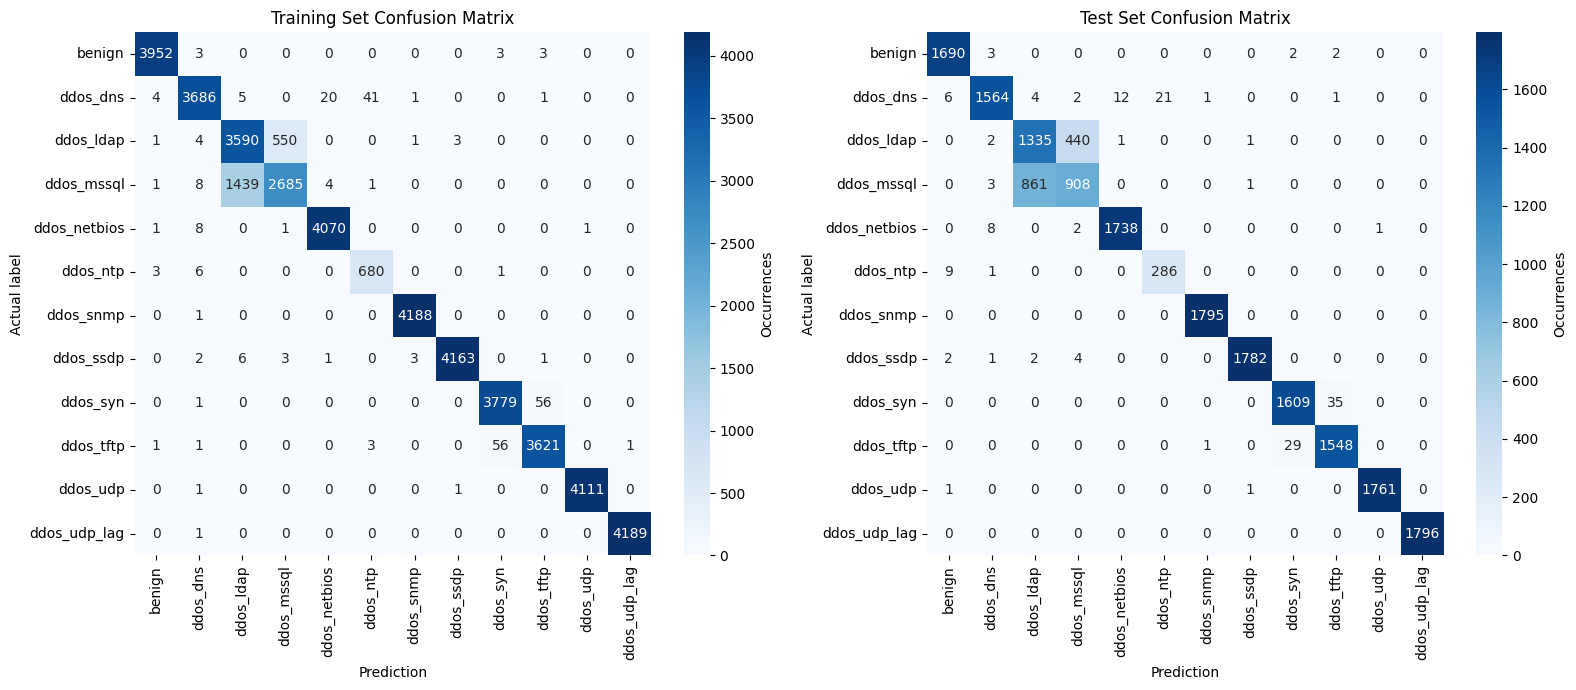

In [ ]:

# k-NN initialized with default parameters (n_neighbors=5)
knn = KNeighborsClassifier()
knn.fit(X_train_scaled, y_train_enc)
y_train_pred_enc = knn.predict(X_train_scaled)
y_test_pred_enc = knn.predict(X_test_scaled)

# Decoded back to Strings for the report
y_train_pred = le.inverse_transform(y_train_pred_enc)
y_test_pred = le.inverse_transform(y_test_pred_enc)

# Text Reports
print('Training set (Baseline)')
print(classification_report(y_train, y_train_pred))
print('Test set (Baseline)')
print(classification_report(y_test, y_test_pred))

#Confusion Matrices computation
confusion_train = confusion_matrix(y_train, y_train_pred)
confusion_test = confusion_matrix(y_test, y_test_pred)

#Plot Side-by-Side
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Plot Train (Left) ---
sns.heatmap(
    confusion_train,
    cmap='Blues',
    annot=True,
    cbar_kws={'label':'Occurrences'},
    fmt='d',
    xticklabels=class_labels,  
    yticklabels=class_labels,
    ax=axes[0] # Directs plot to left subplot
)
axes[0].set_xlabel('Prediction')
axes[0].set_ylabel('Actual label')
axes[0].set_title('Training Set Confusion Matrix')

# --- Plot Test (Right) ---
sns.heatmap(
    confusion_test,
    cmap='Blues', 
    annot=True,
    cbar_kws={'label':'Occurrences'},
    fmt='d',
    xticklabels=class_labels,  
    yticklabels=class_labels,
    ax=axes[1] # Directs plot to right subplot
)
axes[1].set_xlabel('Prediction')
axes[1].set_ylabel('Actual label')
axes[1].set_title('Test Set Confusion Matrix')

plt.tight_layout()
plt.savefig("../images/pdf/kNN_stratified_confusion_matrix_baseline.pdf")  
plt.show()

### hyperparameters tuning & cross-validation

In [ ]:

grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15], 
    'weights': ['uniform', 'distance'],
    'metric': ['minkowski'],
    'p': [1, 2] # 1=Manhattan, 2=Euclidean
}

scoring_metrics = {
    'accuracy': make_scorer(accuracy_score),
    'f1': make_scorer(f1_score, average='weighted')
}

# GridSearchCV creation
grid_search = GridSearchCV(
    estimator = KNeighborsClassifier(), 
    param_grid = grid, 
    n_jobs = -1, 
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42), 
    scoring = scoring_metrics,
    refit = 'accuracy', # Optimizes for accuracy
    error_score = 0
)

# Fit the model
grid_search_result = grid_search.fit(X_train_scaled, y_train_enc)

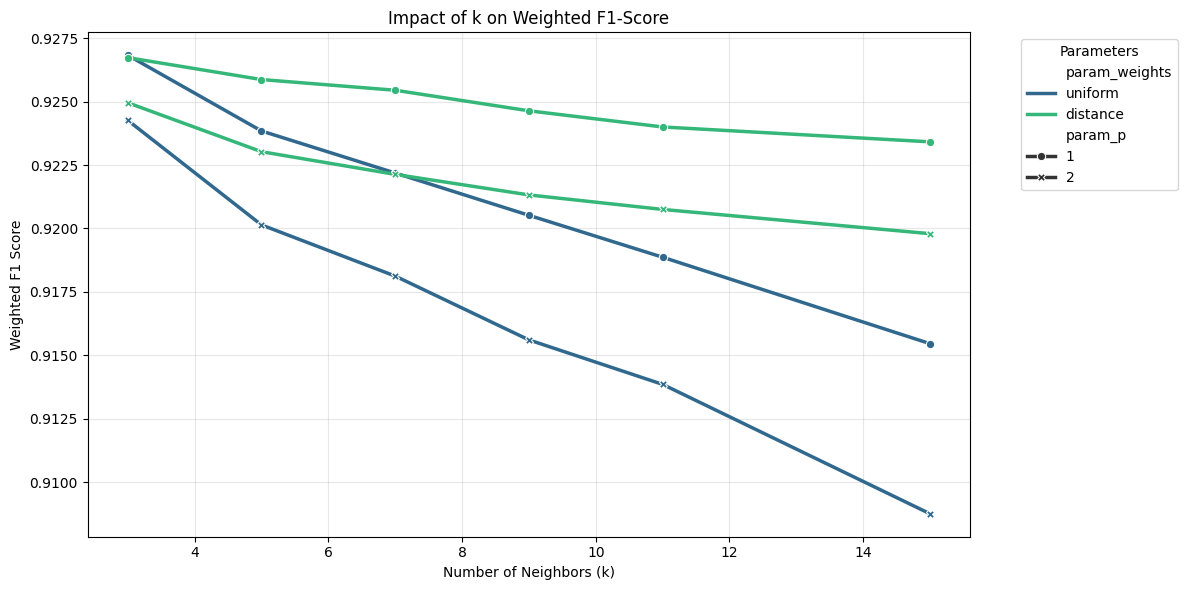

In [ ]:
#Grid Search Results to DataFrame conversion
results_df = pd.DataFrame(grid_search_result.cv_results_)

# Filter/Clean specific columns for plotting
plot_df = results_df[[
    'param_n_neighbors', 
    'param_weights', 
    'param_p', 
    'mean_test_accuracy', 
    'mean_test_f1'
]].copy()  


plot_df['param_n_neighbors'] = plot_df['param_n_neighbors'].astype(int)

plt.figure(figsize=(12, 6))

# We use a lineplot. 
# x-axis: The complexity parameter (k)
# y-axis: The metric (F1 Score)
# hue: Splits lines by 'weights' (uniform vs distance)
# style: Splits lines by 'p' (Manhattan vs Euclidean vs Cubic)
sns.lineplot(
    data=plot_df, 
    x='param_n_neighbors', 
    y='mean_test_f1', 
    hue='param_weights', 
    style='param_p',
    markers=True, 
    dashes=False,
    palette='viridis',
    linewidth=2.5
)

plt.title('Impact of k on Weighted F1-Score')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Weighted F1 Score')
plt.grid(True, alpha=0.3)
plt.legend(title='Parameters', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

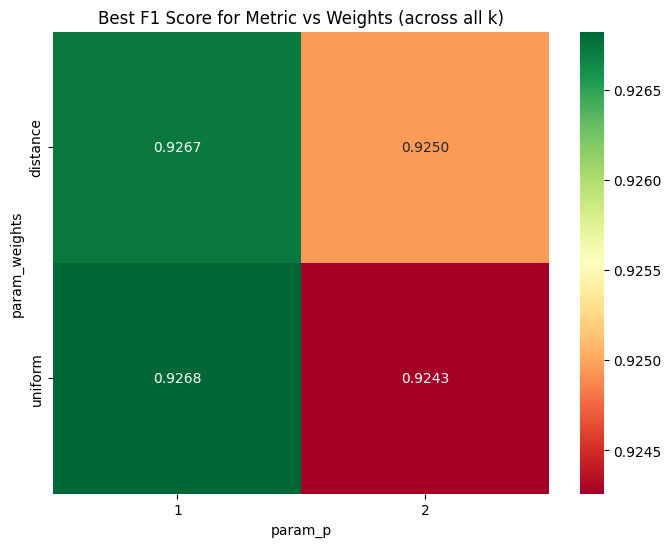

In [ ]:
# Pivot table for the Heatmap
# We aggregate by taking the mean score for each combination of p and weights
pivot_table = results_df.pivot_table(
    values='mean_test_f1', 
    index='param_weights', 
    columns='param_p', 
    aggfunc='max' # We take the max score achieved (best k) for that combo
)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_table, annot=True, cmap='RdYlGn', fmt='.4f')
plt.title('Best F1 Score for Metric vs Weights (across all k)')
plt.show()

Best validation set: 0.927888 using {'metric': 'minkowski', 'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}


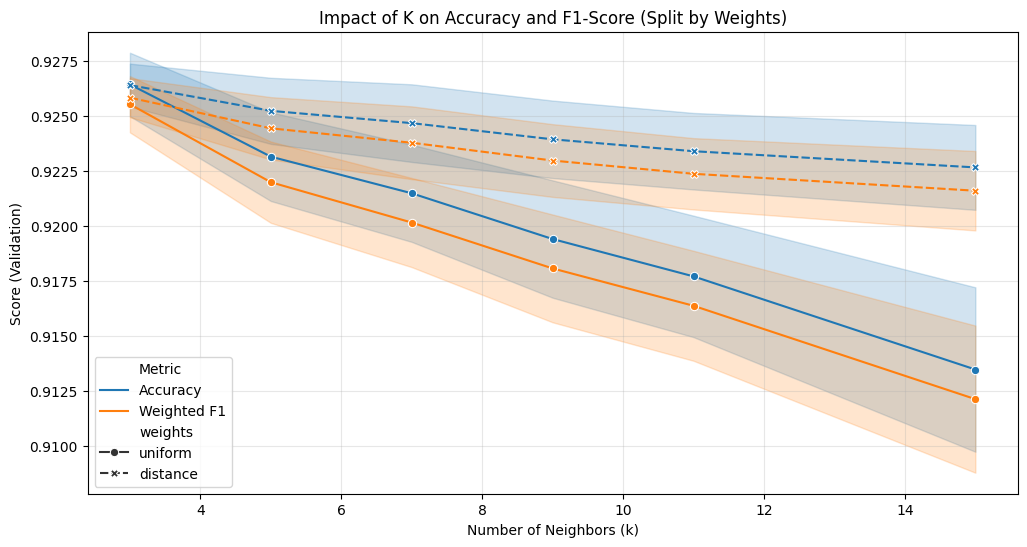

In [ ]:
#Grid Search Results
print("Best validation set: %f using %s" % (grid_search_result.best_score_, grid_search_result.best_params_))

plot_df_2 = results_df[[
    'param_n_neighbors', 
    'param_weights', 
    'param_p',
    'mean_test_accuracy', 
    'mean_test_f1'
]]

# Column names clean up for the legend
plot_df_2.columns = ['k', 'weights', 'p', 'Accuracy', 'Weighted F1']

# DataFrame melted to have both metrics in a single column (Tidy Data format)
# This allows us to plot both Accuracy and F1 on the same chart or subplots easily
df_melted = plot_df_2.melt(
    id_vars=['k', 'weights', 'p'], 
    value_vars=['Accuracy', 'Weighted F1'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))


sns.lineplot(
    data=df_melted, 
    x='k', 
    y='Score', 
    hue='Metric',        
    style='weights',     
    markers=True, 
    dashes=True
)

plt.title('Impact of K on Accuracy and F1-Score (Split by Weights)')
plt.ylabel('Score (Validation)')
plt.xlabel('Number of Neighbors (k)')
plt.grid(True, alpha=0.3)
plt.savefig("../images/pdf/kNN_stratified_k_vs_metrics.pdf")
plt.show()

/var/folders/h0/t58lk1bd34q421y57mvvjs8h0000gn/T/ipykernel_4314/1843787297.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['Manhattan (p=1)', 'Euclidean (p=2)'])


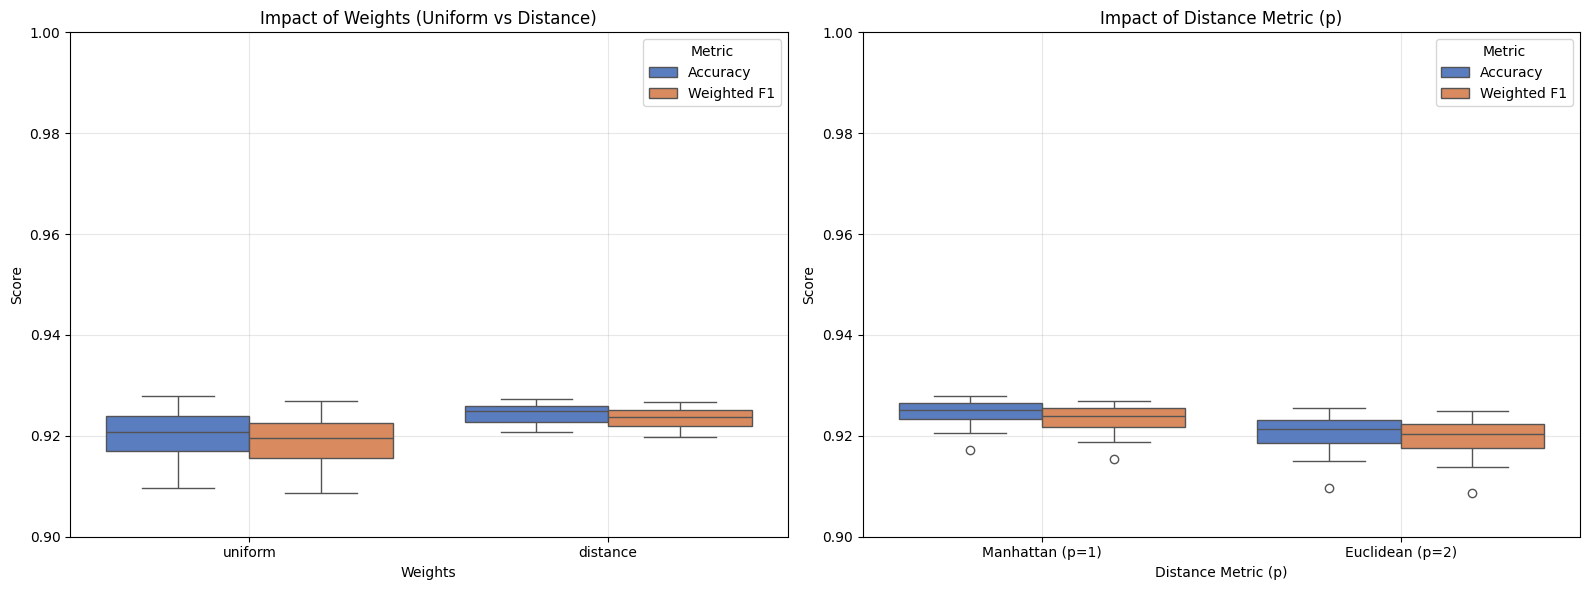

In [ ]:
subset_df = results_df[[
    'param_weights', 
    'param_p',
    'mean_test_accuracy', 
    'mean_test_f1'
]]

# Renamed for readability
subset_df.columns = ['Weights', 'Distance Metric (p)', 'Accuracy', 'Weighted F1']

# Melt for side-by-side plotting of metrics
df_melted = subset_df.melt(
    id_vars=['Weights', 'Distance Metric (p)'], 
    value_vars=['Accuracy', 'Weighted F1'],
    var_name='Metric',
    value_name='Score'
)


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Impact of Weights ---
# We use a boxplot to show the distribution of scores for each weight type.
# The "spread" of the box represents the variance caused by changing 'k' and 'p'.
sns.boxplot(
    data=df_melted,
    x='Weights',
    y='Score',
    hue='Metric',
    ax=axes[0],
    palette='muted'
)
axes[0].set_title('Impact of Weights (Uniform vs Distance)')
axes[0].set_ylim(0.90, 1) # Assuming scores are 0-1
axes[0].grid(True, alpha=0.3)

# --- Plot 2: Impact of Metric (p) ---
sns.boxplot(
    data=df_melted,
    x='Distance Metric (p)',
    y='Score',
    hue='Metric',
    ax=axes[1],
    palette='muted'
)

axes[1].set_xticklabels(['Manhattan (p=1)', 'Euclidean (p=2)'])
axes[1].set_title('Impact of Distance Metric (p)')
axes[1].set_ylim(0.90, 1)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../images/pdf/kNN_stratified_weights_vs_metrics.pdf")
plt.show()

In [ ]:

columns_to_keep = [
    'param_n_neighbors', 
    'param_weights', 
    'param_p', 
    'mean_test_accuracy', 
    'std_test_accuracy',
    'mean_test_f1',
    'std_test_f1',
    'rank_test_accuracy' # or rank_test_f1
]
analysis_df = results_df[columns_to_keep]

# Columns renamed for easier reading 
analysis_df.columns = ['k', 'weights', 'p', 'Mean Acc', 'Std Acc', 'Mean F1', 'Std F1', 'Rank']

# --- OUTPUT 1: The Top 5 Configurations ---
print(">>> TOP 5 CONFIGURATIONS:")
print(analysis_df.sort_values(by='Rank').head(5).to_string(index=False))
print("\n" + "="*50 + "\n")

# --- OUTPUT 2: Impact of Weights (Aggregated) ---
print(">>> IMPACT OF WEIGHTS (Averaged over all k and p):")
print(analysis_df.groupby('weights')[['Mean Acc', 'Mean F1']].mean())
print("\n" + "="*50 + "\n")

# --- OUTPUT 3: Impact of Distance Metric (Aggregated) ---
print(">>> IMPACT OF P (Averaged over all k and weights):")
print(analysis_df.groupby('p')[['Mean Acc', 'Mean F1']].mean())

>>> TOP 5 CONFIGURATIONS:
 k  weights  p  Mean Acc  Std Acc  Mean F1   Std F1  Rank
 3  uniform  1  0.927888 0.003021 0.926823 0.003049     1
 3 distance  1  0.927391 0.002803 0.926729 0.002820     2
 5 distance  1  0.926746 0.002925 0.925866 0.002982     3
 7 distance  1  0.926450 0.002703 0.925445 0.002763     4
 9 distance  1  0.925709 0.002650 0.924635 0.002679     5


>>> IMPACT OF WEIGHTS (Averaged over all k and p):
          Mean Acc   Mean F1
weights                     
distance  0.924391  0.923505
uniform   0.920276  0.919038


>>> IMPACT OF P (Averaged over all k and weights):
   Mean Acc   Mean F1
p                    
1  0.924379  0.923149
2  0.920288  0.919395


### Learning curve

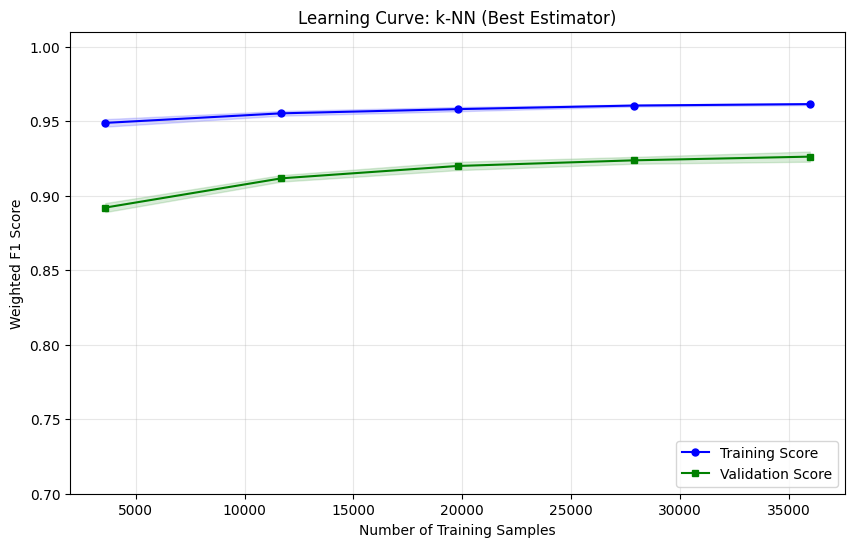

In [ ]:

# The best estimator found by your Grid Search
best_model = grid_search_result.best_estimator_

# Training sizes definition: 5 points from 10% to 100%
train_sizes = np.linspace(0.1, 1.0, 5)

# Learning Curve
# n_jobs=-1 uses all cores
# shuffle=True ensures we don't just pick the first N rows (which might be sorted)
train_sizes_abs, train_scores, test_scores = learning_curve(
    estimator=best_model,
    X=X_train_scaled,
    y=y_train_enc,
    train_sizes=train_sizes,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_weighted', 
    n_jobs=-1,
    shuffle=True,
    random_state=42
)

# Means and Standard Deviations
# We average across the CV folds for each training size
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)


plt.figure(figsize=(10, 6))

# Training Score
plt.plot(train_sizes_abs, train_mean, color='blue', marker='o', markersize=5, label='Training Score')
plt.fill_between(train_sizes_abs, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

# Validation Score
plt.plot(train_sizes_abs, test_mean, color='green', marker='s', markersize=5, label='Validation Score')
plt.fill_between(train_sizes_abs, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

# Formatting
plt.title('Learning Curve: k-NN (Best Estimator)')
plt.xlabel('Number of Training Samples')
plt.ylabel('Weighted F1 Score')
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right')
plt.ylim(0.7, 1.01) 

plt.show()

Generating predictions with best model...
--- Training Set Report ---
              precision    recall  f1-score   support

      benign       1.00      1.00      1.00      3961
    ddos_dns       0.99      0.99      0.99      3758
   ddos_ldap       0.77      0.91      0.83      4149
  ddos_mssql       0.89      0.73      0.80      4138
ddos_netbios       0.99      1.00      1.00      4081
    ddos_ntp       0.96      0.99      0.98       690
   ddos_snmp       1.00      1.00      1.00      4189
   ddos_ssdp       1.00      1.00      1.00      4179
    ddos_syn       0.99      0.99      0.99      3836
   ddos_tftp       0.99      0.99      0.99      3683
    ddos_udp       1.00      1.00      1.00      4113
ddos_udp_lag       1.00      1.00      1.00      4190

    accuracy                           0.96     44967
   macro avg       0.97      0.97      0.96     44967
weighted avg       0.96      0.96      0.96     44967


--- Test Set Report ---
              precision    recall  f1-

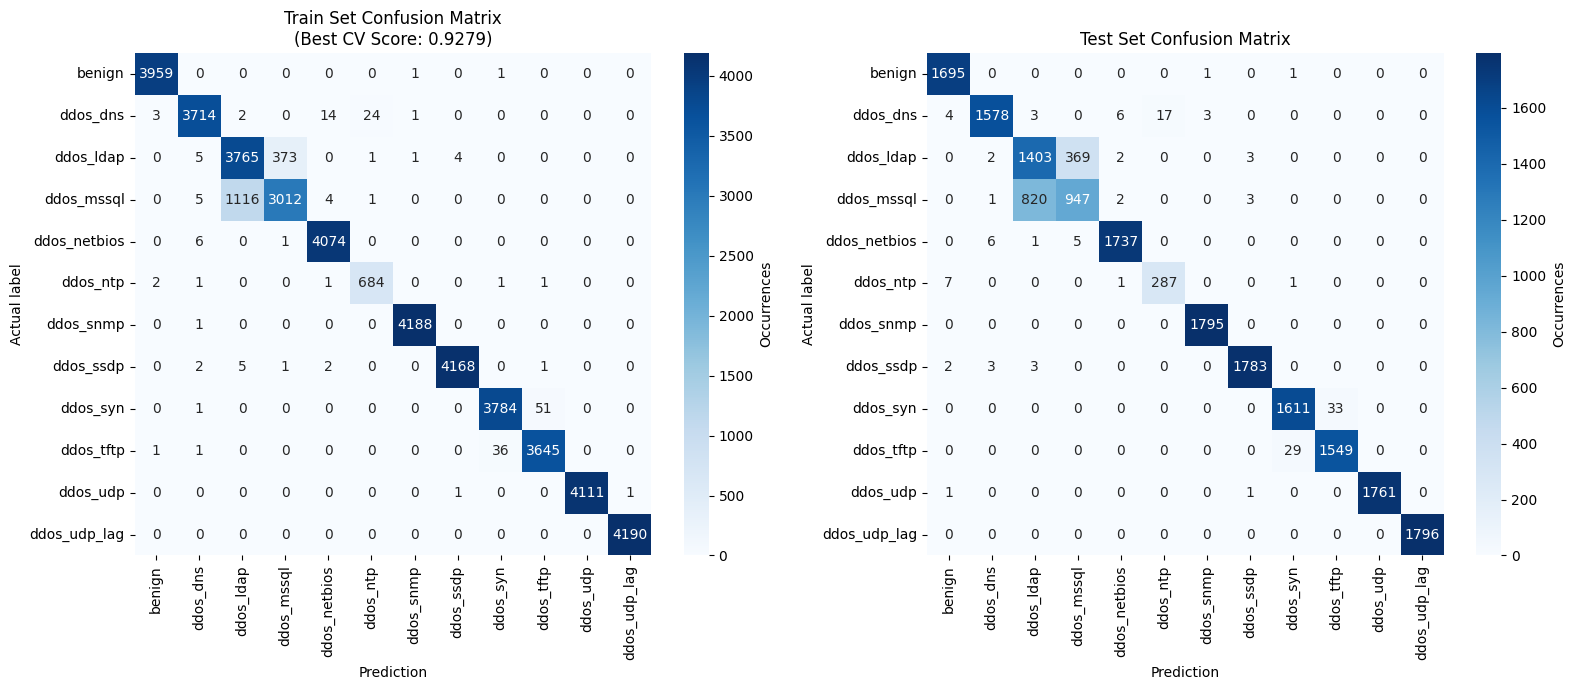

In [ ]:
# Best Model
best_model = grid_search_result.best_estimator_

# Predictions generation
print("Generating predictions with best model...")
y_train_pred_enc_best = best_model.predict(X_train_scaled)
y_test_pred_enc_best = best_model.predict(X_test_scaled)

# Integers decoded back to Strings before reporting
y_train_pred_best = le.inverse_transform(y_train_pred_enc_best)
y_test_pred_best = le.inverse_transform(y_test_pred_enc_best)


print('--- Training Set Report ---')
print(classification_report(y_train, y_train_pred_best))
print('\n--- Test Set Report ---')
print(classification_report(y_test, y_test_pred_best))

# Confusion Matrices
confusion_train = confusion_matrix(y_train, y_train_pred_best)
confusion_test = confusion_matrix(y_test, y_test_pred_best)


fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Plot Train (Left) ---
sns.heatmap(
    confusion_train,
    cmap='Blues',
    annot=True,
    cbar_kws={'label':'Occurrences'},
    fmt='d',
    xticklabels=class_labels,  
    yticklabels=class_labels,
    ax=axes[0] 
)
axes[0].set_xlabel('Prediction')
axes[0].set_ylabel('Actual label')
axes[0].set_title(f'Train Set Confusion Matrix\n(Best CV Score: {grid_search_result.best_score_:.4f})')

# --- Plot Test (Right) ---
sns.heatmap(
    confusion_test,
    cmap='Blues', 
    annot=True,
    cbar_kws={'label':'Occurrences'},
    fmt='d',
    xticklabels=class_labels,  
    yticklabels=class_labels,
    ax=axes[1] 
)
axes[1].set_xlabel('Prediction')
axes[1].set_ylabel('Actual label')
axes[1].set_title('Test Set Confusion Matrix')

plt.tight_layout()
plt.savefig("../images/pdf/kNN_stratified_confusion_matrix_best_model.pdf")
plt.show()